# Epidemics in Python with `gemlib`

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gem-epidemics/colab/blob/master/eitv/gemlib_workshop.ipynb)

This notebook is a 90-minute workshop on simulating epidemic models with
[`gemlib`](https://gem-epidemics.gitlab.io/gemlib). It assumes some familiarity with R
and a little Python.

| Part | Topic | Time |
|---|---|---|
| 1 | Just enough Python | ~20 min |
| 2 | Models in `gemlib` | ~65 min |
| | Wrap-up | ~5 min |

## LEARNING OUTCOMES
- Use NumPy arrays, matrix multiplication and functions in the way `gemlib` expects
- Describe an epidemic model by its incidence matrix, transition-rate functions and initial state
- Simulate single-population and metapopulation models in `gemlib`
- Compare deterministic, continuous-time and discrete-time solvers for the same model

Run the cells from top to bottom. Exercises have hidden solutions below them; try the
exercise first, then expand the solution if you get stuck.

## Setup

If you are using Google Colab, uncomment and run the `pip install` line first. If you
are using the course environment, `gemlib` is already installed.

In [1]:
# !pip install gemlib

import numpy as np
import matplotlib.pyplot as plt

## Part 1: Just enough Python

This part covers only the Python that the `gemlib` examples use.

| | R | Python |
|---|---|---|
| Assignment | `x <- 5` | `x = 5` |
| Numeric vector | `c(1, 2, 3)` | `np.array([1, 2, 3])` |
| First element | `x[1]` | `x[0]` (**Python counts from 0**) |
| Elements 2 to 3 | `x[2:3]` | `x[1:3]` (the end of a slice is **excluded**) |
| Load a package | `library(dplyr)` | `import numpy as np` |
| Code blocks | `{ ... }` | indentation (4 spaces) |
| Define a function | `f <- function(x) { x^2 }` | `def f(x):`<br>`    return x**2` |
| Matrix multiplication | `A %*% x` | `A @ x` |
| Help | `?rbinom` | `help(np.random.binomial)` |

### Arrays

NumPy arrays behave much like R vectors and matrices, and arithmetic on them is
element-wise. In `gemlib`, the state of an epidemic is a 2-D array with one **row per
population** (or "unit": a farm, a town) and one **column per compartment**.

In [2]:
#                  S   I   R
state = np.array([[90, 10,  0],   # unit 0
                  [95,  5,  0],   # unit 1
                  [80, 15,  5]],  # unit 2
                 dtype=np.float32)

print(state.shape)           # (rows, columns)
print(state[0, 1])           # unit 0, compartment I
print(state[:, 1])           # the I column for every unit
print(state.sum(axis=-1))    # unit sizes: sum across the last axis (the compartments)
print(state[:, 1] / state.sum(axis=-1))   # proportion infected in each unit

(3, 3)
10.0
[10.  5. 15.]
[100. 100. 100.]
[0.1  0.05 0.15]


`state[:, 1]` reads "all rows, column 1", and `axis=-1` means "the last axis". You will see
both in every `gemlib` model below. `dtype=np.float32` stores the numbers as single-precision
floats, which is what `gemlib` expects.

### Matrix multiplication

Suppose a **connectivity matrix** says how strongly each pair of units is linked: row $i$
gives the weight unit $i$ puts on each other unit's infections. The infection pressure on
unit $i$ from the other units is the sum over $j$ of `connectivity[i, j] * prop_inf[j]`,
which is a single matrix multiplication.

In [3]:
connectivity = np.array([
    [0.0, 0.6, 0.5],
    [0.5, 0.0, 0.3],
    [0.4, 0.3, 0.0],
])
prop_inf = state[:, 1] / state.sum(axis=-1)

connectivity @ prop_inf

array([0.105, 0.095, 0.055])

````{exercise-start}
:label: gemlib_ex1
````

A unit's **force of infection** combines a within-unit term with the between-unit term:

$$
\lambda_i = \beta \left[\, \text{prop\_inf}_i + \psi \,(C \cdot \text{prop\_inf})_i \,\right]
$$

1. Using `beta = 0.3` and `psi = 0.5`, compute the force of infection for all three
   units in one line (no loop).
2. Which unit has the highest force of infection? (Hint: `np.argmax`.)

In [4]:
# your code here

````{exercise-end}
````

````{solution-start} gemlib_ex1
:class: dropdown
````

In [5]:
beta = 0.3
psi = 0.5

foi = beta * (prop_inf + psi * (connectivity @ prop_inf))
print(foi)
print(f"Unit {np.argmax(foi)} has the highest force of infection")

[0.04575 0.02925 0.05325]
Unit 2 has the highest force of infection


````{solution-end}
````

### Functions

Functions are defined with `def`, and the body is indented. In `gemlib`, each transition
rate is a small function, and the model is given a **list** of them. Python functions are
ordinary objects, so they can be stored in a list and called in turn.

In [6]:
def si_rate(t, state):
    return 0.3 * state[:, 1] / state.sum(axis=-1)


def ir_rate(t, state):
    return 0.1


rate_fns = [si_rate, ir_rate]

for fn in rate_fns:
    print(fn(0.0, state))

[0.03  0.015 0.045]
0.1


### Plotting

`matplotlib` is the standard plotting library. Most plots follow this pattern: make a
figure and axes, draw on the axes, then label them.

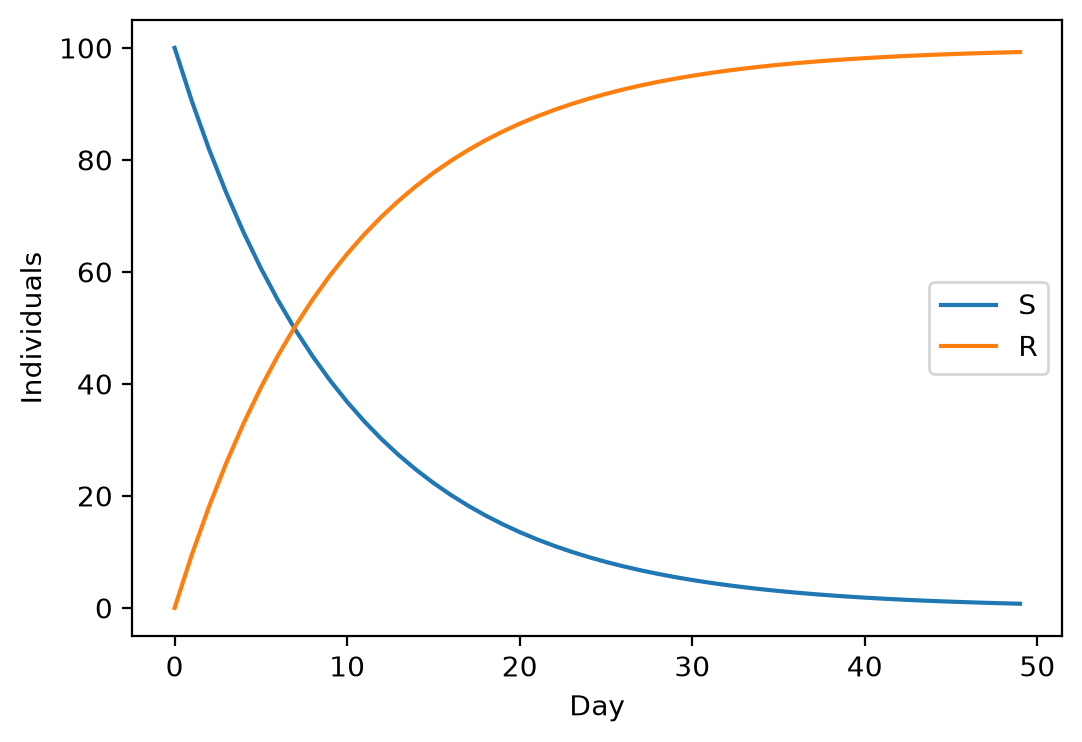

In [7]:
days = np.arange(50)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(days, 100 * np.exp(-0.1 * days), label="S")
ax.plot(days, 100 - 100 * np.exp(-0.1 * days), label="R")
ax.set_xlabel("Day")
ax.set_ylabel("Individuals")
ax.legend()
plt.show()

## Part 2: Models in `gemlib`

`gemlib` is a library for implementing infectious disease models. You describe a model
once, and `gemlib` gives you deterministic and stochastic simulation and, importantly, the
probability functions needed for parameter inference.

__Documentation__: https://gem-epidemics.gitlab.io/gemlib

A model is described by three things:

1. An **incidence matrix**, with one row per compartment and one column per transition. Each
   column gives the change in each compartment when a *single individual* makes that transition.
2. A list of **transition-rate functions**, one per transition. Each takes `(t, state)` and
   returns the per-individual rate for every unit. Use `jnp` (JAX's version of NumPy) rather than
   `np` for any maths inside them.
3. An **initial state**, of shape `[units, compartments]`, even when there is only one unit.

In [8]:
import jax
import jax.numpy as jnp
from matplotlib.lines import Line2D

import gemlib

gld = gemlib.distributions

### An SIR model

In the homogeneously mixing SIR model, the per-individual transition rates are

$$
\lambda^{SI}_t = \beta I_t / N, \qquad \lambda^{IR}_t = \gamma.
$$

The discrete-time solver advances the state one day at a time. Each individual in the source
compartment makes the transition with probability $1 - e^{-\lambda \Delta t}$ (the
*chain-binomial* model).

In [9]:
sir_incidence = np.array([
    # SI  IR
    [-1,  0],   # S
    [ 1, -1],   # I
    [ 0,  1],   # R
], dtype=np.float32)

sir_initial = np.array([[99, 1, 0]], dtype=np.float32)   # one unit (row)

beta, gamma = 0.1, 0.05


def si_rate(t, state):
    return beta * state[:, 1] / state.sum(axis=-1)


def ir_rate(t, state):
    return gamma


sir_model = gld.DiscreteTimeStateTransitionModel(
    transition_rate_fn=[si_rate, ir_rate],
    incidence_matrix=sir_incidence,
    initial_state=sir_initial,
    num_steps=200,
)

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


`sample` draws simulated epidemics, using a JAX random `seed` (the equivalent of
`set.seed()` in R). The result is a set of **events**: an array of shape `[B, T, N, R]`,
where `B` is the number of simulations, `T` the number of time steps, `N` the number of
units and `R` the number of transitions. `compute_state` turns the events back into the
state over time, with shape `[B, T, N, compartments]`.

In [10]:
sir_events = sir_model.sample(sample_shape=50, seed=jax.random.key(0))
print(sir_events.shape)

sir_states = sir_model.compute_state(sir_events)
print(sir_states.shape)

(50, 200, 1, 2)
(50, 200, 1, 3)


Here is a small helper to plot the result: one line per simulation, coloured by compartment.

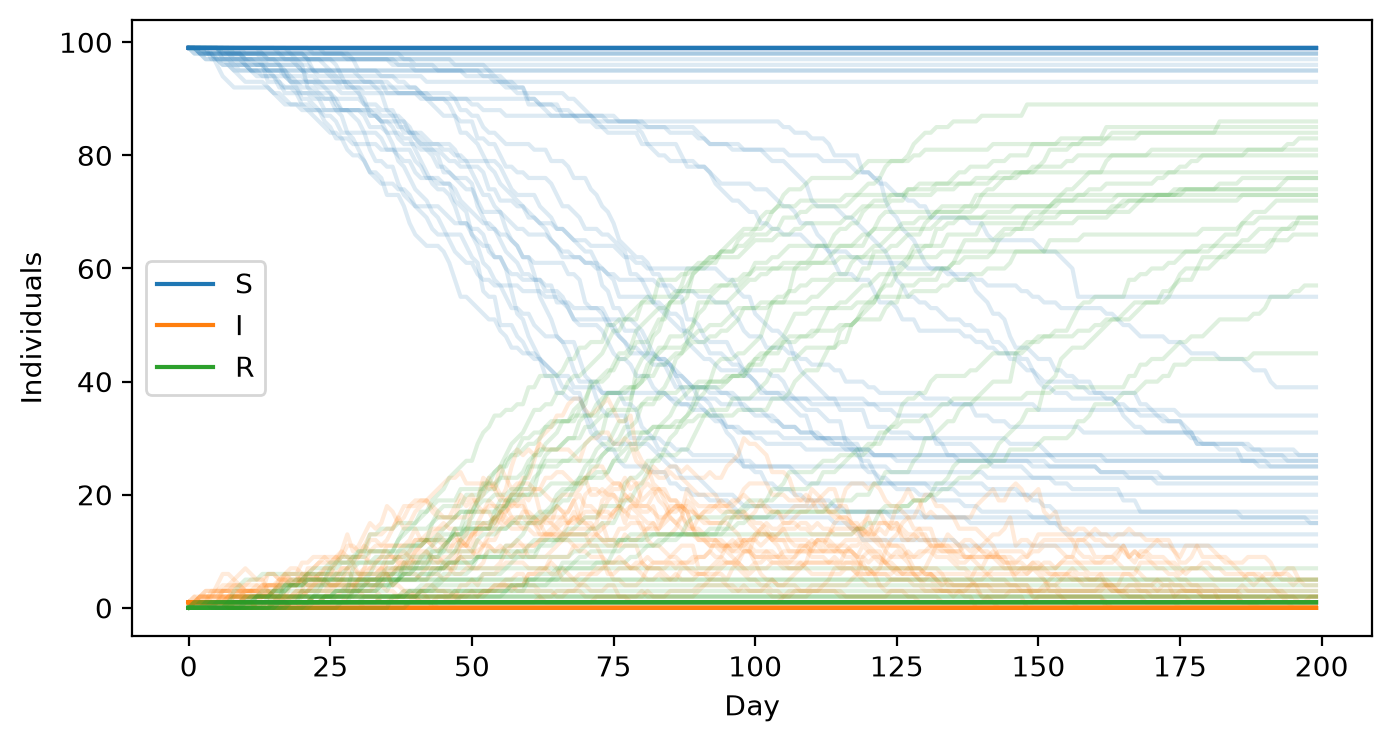

In [11]:
def plot_states(states, labels, ax=None, alpha=1.0):
    "Plot states of shape [simulations, time, compartments], one colour per compartment."
    states = np.asarray(states)
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 4))
    for k, label in enumerate(labels):
        ax.plot(states[..., k].T, color=f"C{k}", alpha=alpha)
        ax.plot([], [], color=f"C{k}", label=label)   # one legend entry per compartment
    ax.set_xlabel("Day")
    ax.set_ylabel("Individuals")
    ax.legend()
    return ax


plot_states(sir_states[:, :, 0, :], ["S", "I", "R"], alpha=0.15)   # unit 0
plt.show()

Every run is different, and some epidemics fade out early by chance.

Because `gemlib` knows the full probability model, it can also tell us how probable a
given set of events is under the model. This **log-likelihood** is the building block for
estimating $\beta$ and $\gamma$ from data.

In [12]:
sir_model.log_prob(sir_events[0])

Array(-3.4176314, dtype=float32)

````{exercise-start}
:label: gemlib_ex2
````

Extend the model to an **SEIR** model by adding an exposed (E) compartment between S and I,
with transition rates

$$
\lambda^{SE}_t = \beta I_t / N, \qquad \lambda^{EI}_t = \nu, \qquad \lambda^{IR}_t = \gamma,
$$

and $\beta = 0.3$, $\nu = 0.5$, $\gamma = 0.2$.

1. Write the incidence matrix (4 compartments, 3 transitions).
2. Write the three transition-rate functions. Careful: I is now column 2.
3. Build a `DiscreteTimeStateTransitionModel` for 100 days starting from `[[99, 0, 1, 0]]`,
   simulate 50 epidemics and plot them.

In [13]:
# your code here

````{exercise-end}
````

````{solution-start} gemlib_ex2
:class: dropdown
````

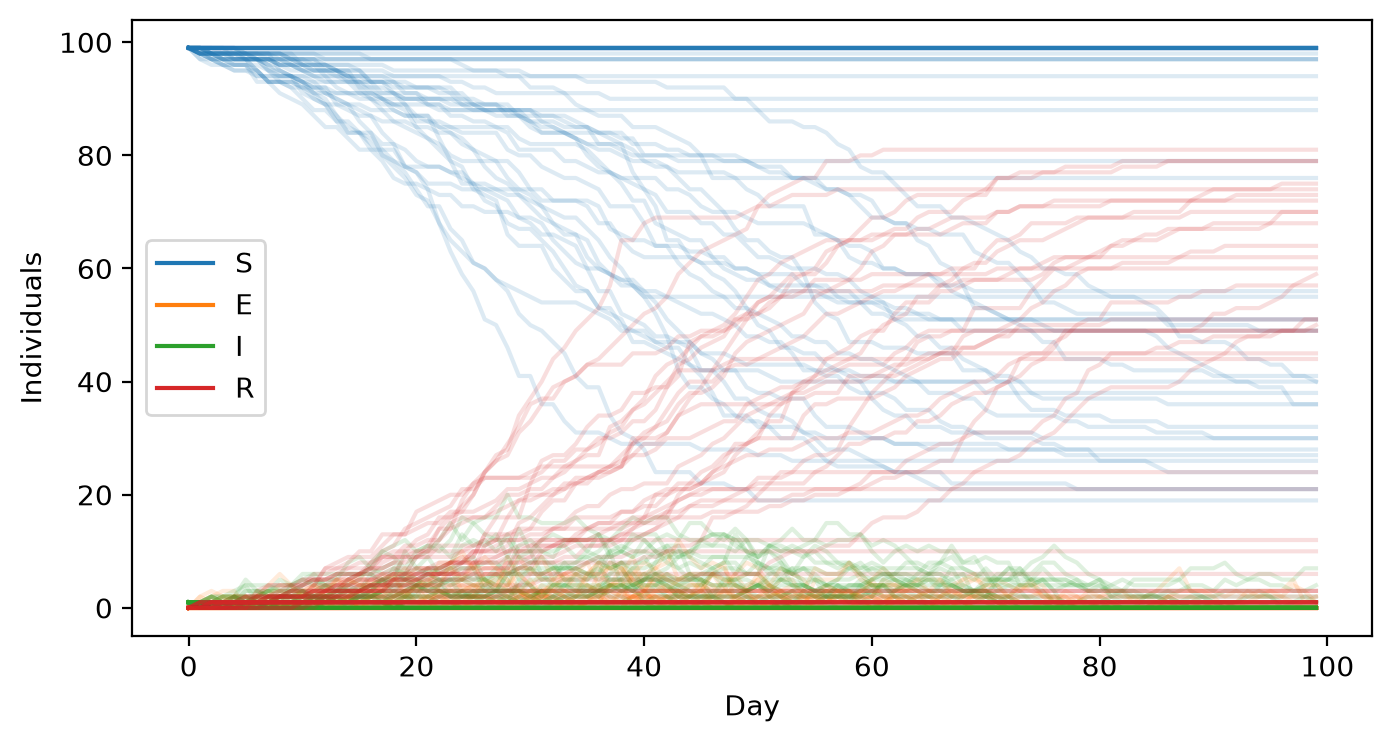

In [14]:
seir1_incidence = np.array([
    # SE  EI  IR
    [-1,  0,  0],   # S
    [ 1, -1,  0],   # E
    [ 0,  1, -1],   # I
    [ 0,  0,  1],   # R
], dtype=np.float32)

seir1_initial = np.array([[99, 0, 1, 0]], dtype=np.float32)


def se_rate(t, state):
    return 0.3 * state[:, 2] / state.sum(axis=-1)


def ei_rate(t, state):
    return 0.5


def ir_rate(t, state):
    return 0.2


seir1_model = gld.DiscreteTimeStateTransitionModel(
    transition_rate_fn=[se_rate, ei_rate, ir_rate],
    incidence_matrix=seir1_incidence,
    initial_state=seir1_initial,
    num_steps=100,
)

seir1_states = seir1_model.compute_state(
    seir1_model.sample(sample_shape=50, seed=jax.random.key(1))
)
plot_states(seir1_states[:, :, 0, :], ["S", "E", "I", "R"], alpha=0.15)
plt.show()

````{solution-end}
````

### A metapopulation SEIR model

We now move to a model of an SEIR epidemic unfolding in 3 connected populations (units),
for example three farms or three towns.

We write $x^{q}_{it}$ for the number of individuals in compartment
$q \in \{\mathrm{S}, \mathrm{E}, \mathrm{I}, \mathrm{R}\}$ in unit $i$ at time $t$, and
$\mathbf{x}_t$ for the whole state at time $t$. The transition rates are

$$
\begin{align}
\lambda^{\mathrm{SE}}_i(\mathbf{x}_t) & = \beta \left[ \frac{x_{it}^{\mathrm{I}}}{n_i} + \psi \left( C \cdot \frac{\mathbf{x}_t^{\mathrm{I}}}{\mathbf{n}} \right)_i \right] \\
\lambda^{\mathrm{EI}}_i(\mathbf{x}_t) & = \nu \\
\lambda^{\mathrm{IR}}_i(\mathbf{x}_t) & = \gamma
\end{align}
$$

where $\mathbf{n}$ is the vector of population sizes and

$$
C = \left(\begin{array}{ccc}
    0 & 0.5 & 0.25 \\
    0.5 & 0 & 0.1 \\
    0.25 & 0.1 & 0
    \end{array}\right)
$$

is a zero-diagonal connectivity matrix between units, and $\psi$ scales how strongly the
units are coupled. This is the force of infection you computed in Exercise 1.

In [15]:
connectivity = np.array([
    [0.0 , 0.5, 0.25],
    [0.5 , 0.0, 0.1 ],
    [0.25, 0.1, 0.0 ],
], dtype=np.float32)

seir_incidence = np.array([
    # SE  EI  IR
    [-1,  0,  0],   # S
    [ 1, -1,  0],   # E
    [ 0,  1, -1],   # I
    [ 0,  0,  1],   # R
], dtype=np.float32)

seir_initial = np.array([
    # S   E  I  R
    [99,  0, 1, 0],   # unit 0
    [100, 0, 0, 0],   # unit 1
    [100, 0, 0, 0],   # unit 2
], dtype=np.float32)

beta, psi, nu, gamma = 0.6, 0.02, 0.5, 0.2


def se_rate(t, state):
    prop_inf = state[:, 2] / state.sum(axis=-1)   # I is column 2 (S, E, I, R)
    return beta * (prop_inf + psi * jnp.matvec(connectivity, prop_inf))


def ei_rate(t, state):
    return nu


def ir_rate(t, state):
    return gamma


seir_rate_fns = [se_rate, ei_rate, ir_rate]

We will plot each unit in its own panel, so here is a small helper function for that.

In [16]:
def plot_units(times, states, labels=("S", "E", "I", "R"), alpha=1.0, height=3.5):
    "Plot states of shape [..., T, N, compartments], one panel per unit."
    states = np.asarray(states)
    times = np.asarray(times)
    num_units = states.shape[-2]
    fig, axes = plt.subplots(1, num_units, figsize=(num_units * height * 1.4, height), sharey=True)
    for i, ax in enumerate(axes):
        for k, label in enumerate(labels):
            ax.plot(times.T, states[..., i, k].T, color=f"C{k}", alpha=alpha)
        ax.set_title(f"Unit {i}")
        ax.set_xlabel("Time")
    axes[0].set_ylabel("Individuals")
    handles = [Line2D([0], [0], color=f"C{k}") for k in range(len(labels))]
    axes[-1].legend(handles, labels)
    return fig, axes

The same model description can now be passed to three different solvers.

#### Deterministic solver

`ode_model` solves the model as a system of ordinary differential equations.

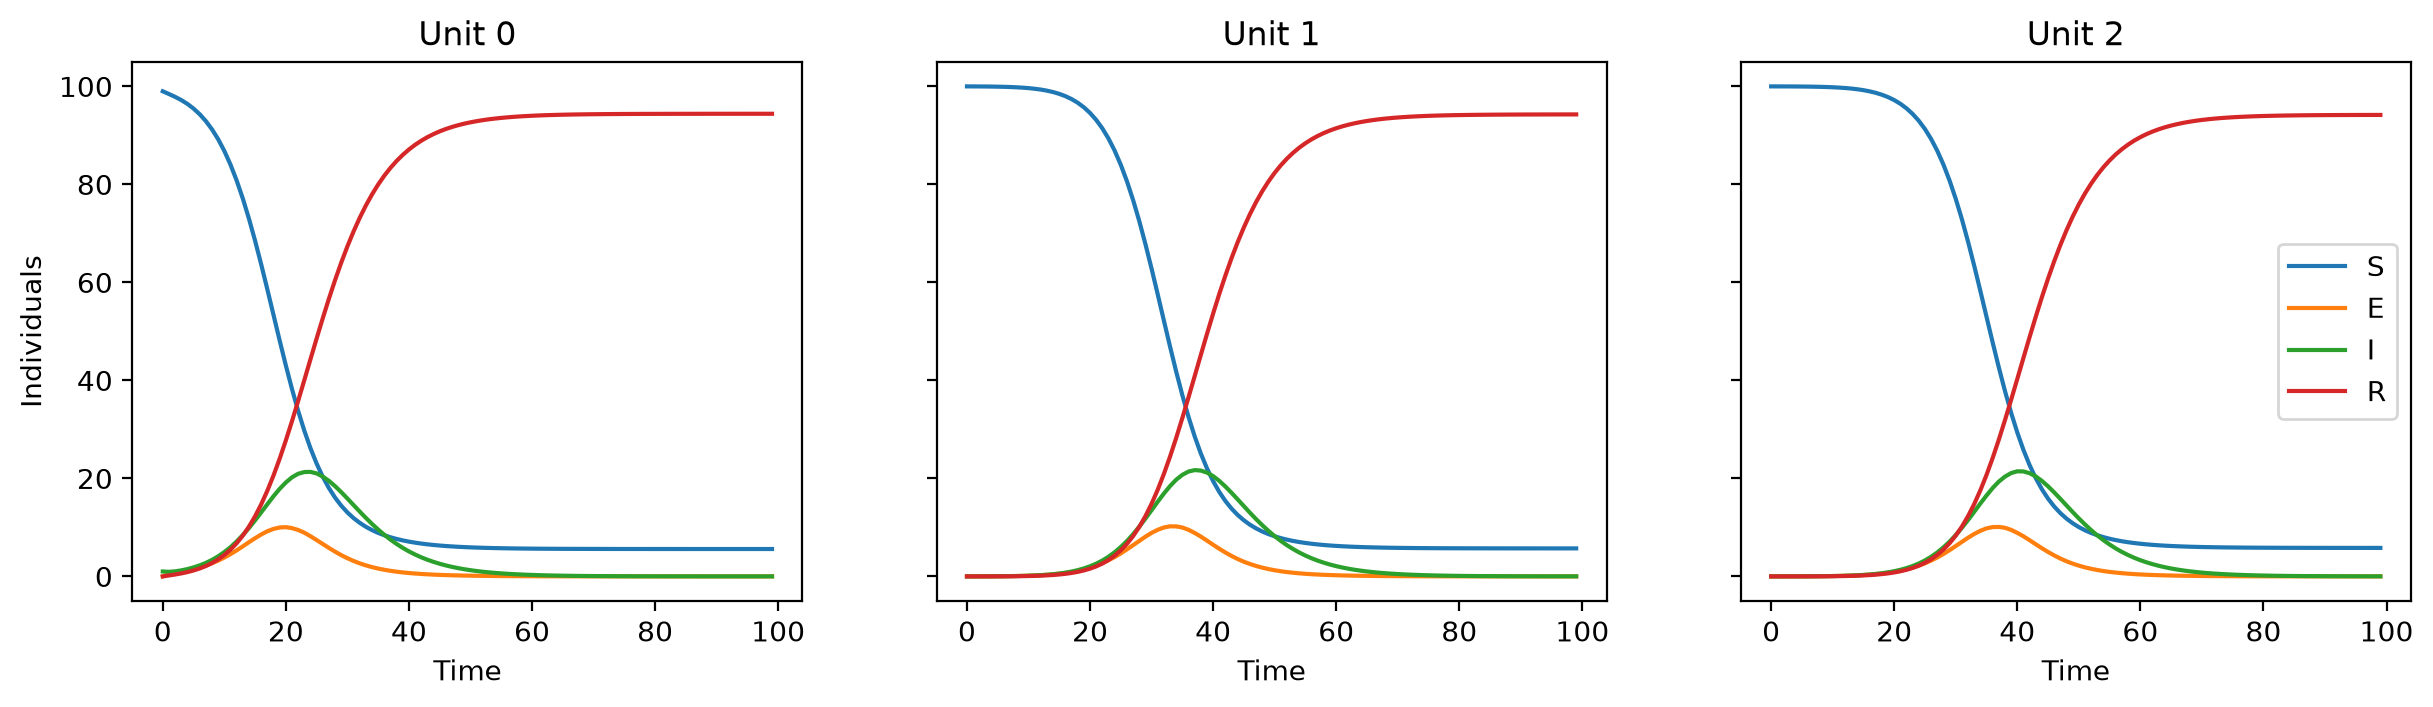

In [17]:
det_sim = gemlib.deterministic.ode_model(
    transition_rate_fn=seir_rate_fns,
    incidence_matrix=seir_incidence,
    initial_state=seir_initial,
    num_steps=100,
    initial_time=0.0,
    time_delta=1.0,
)

plot_units(det_sim.times, det_sim.states)
plt.show()

#### Continuous-time stochastic solver

This simulates the model as a continuous-time Markov jump process using the
[Gillespie algorithm](https://en.wikipedia.org/wiki/Gillespie_algorithm). The output is an
**event list** recording which transition happened in which unit, and when; `num_steps` is
the maximum number of events to simulate.

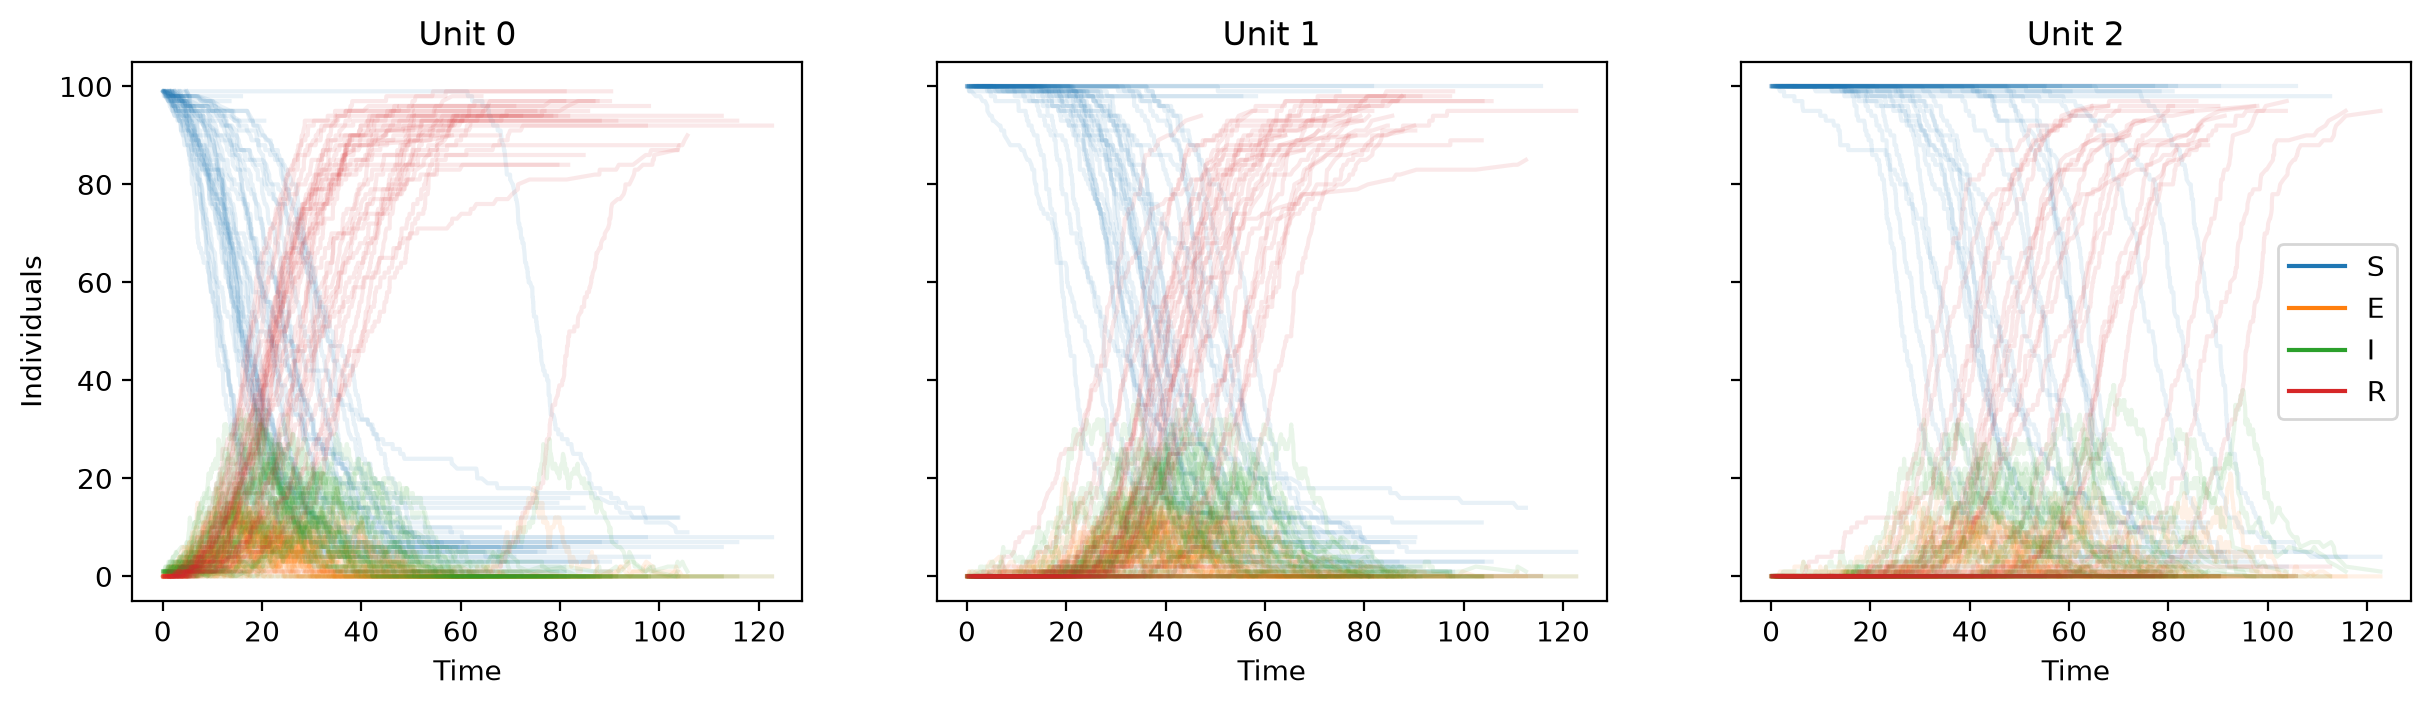

In [18]:
cont_model = gld.ContinuousTimeStateTransitionModel(
    transition_rate_fn=seir_rate_fns,
    incidence_matrix=seir_incidence,
    initial_state=seir_initial,
    num_steps=1200,
)

cont_events = cont_model.sample(50, seed=jax.random.key(1))
cont_states = cont_model.compute_state(cont_events)

plot_units(cont_events.time, cont_states, alpha=0.1)
plt.show()

#### Discrete-time stochastic solver

This is the chain-binomial solver we used for the SIR model, now for three connected units.

In [ ]:
disc_model = gld.DiscreteTimeStateTransitionModel(
    transition_rate_fn=seir_rate_fns,
    incidence_matrix=seir_incidence,
    initial_state=seir_initial,
    num_steps=100,
)

disc_events = disc_model.sample(sample_shape=50, seed=jax.random.key(0))
disc_states = disc_model.compute_state(disc_events)

plot_units(np.arange(100), disc_states, alpha=0.1)
plt.show()

````{exercise-start}
:label: gemlib_ex3
````

Pick one or more of the following, using the discrete-time model:

1. **Isolate a unit.** Edit `connectivity` so that unit 2 has no contact with the other units.
   What happens to the epidemic in unit 2?
2. **Strengthen the links.** Increase `psi` from 0.02 to 0.5. How does this change the timing of
   the epidemics in units 1 and 2 relative to unit 0?
3. **Move the seed.** Start the epidemic in unit 2 instead of unit 0.

Remember to rebuild the model (re-run `gld.DiscreteTimeStateTransitionModel(...)`) after
changing anything it depends on.

In [ ]:
# your code here

````{exercise-end}
````

````{solution-start} gemlib_ex3
:class: dropdown
````

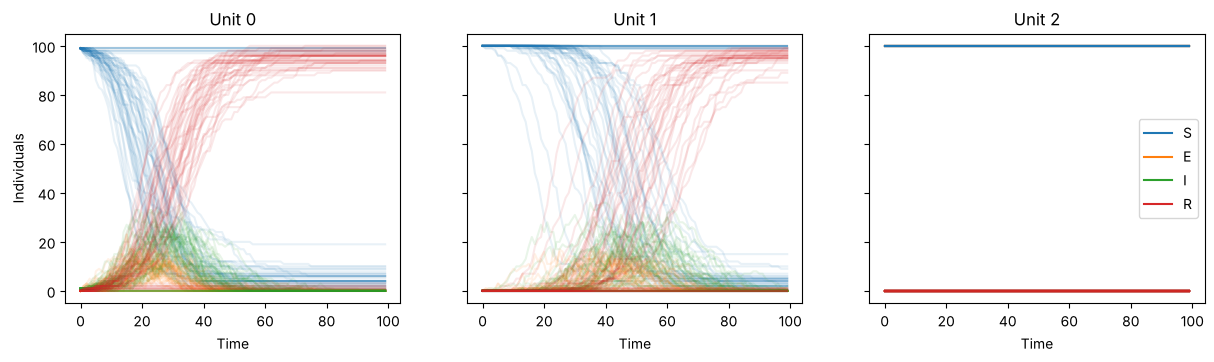

In [ ]:
# 1. Isolate unit 2: zero its row and column in the connectivity matrix
connectivity = np.array([
    [0.0, 0.5, 0.0],
    [0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0],
], dtype=np.float32)

isolated_model = gld.DiscreteTimeStateTransitionModel(
    transition_rate_fn=seir_rate_fns,
    incidence_matrix=seir_incidence,
    initial_state=seir_initial,
    num_steps=100,
)
isolated_states = isolated_model.compute_state(
    isolated_model.sample(sample_shape=50, seed=jax.random.key(0))
)
plot_units(np.arange(100), isolated_states, alpha=0.1)
plt.show()

# Unit 2 never becomes infected: with no contact, it has zero force of infection.

````{solution-end}
````

## Wrap-up

Today we have:

- used just enough NumPy (2-D arrays, `axis=-1`, matrix multiplication) and functions to describe models;
- described epidemic models in `gemlib` as an **incidence matrix + transition-rate functions + initial state**;
- simulated SIR and SEIR models, and computed the log-likelihood of a simulated epidemic;
- run a metapopulation model with deterministic, continuous-time and discrete-time solvers.

### Where next?

- The `gemlib` [documentation](https://gem-epidemics.gitlab.io/gemlib) covers parameter
  inference, which builds on the `log_prob` method we saw above.
- The full course notebooks cover Python in more depth (data types, `pandas`, decorators)
  and the theory of state-transition models.